# **CNN Rock-Paper-Scissor Classifiction by Md. Raihan Hossen (220105)**

# At first, I will import necessary packages.

In [87]:
import os
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.datasets.utils import download_and_extract_archive

from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import glob
from sklearn.metrics import confusion_matrix
import time
import json
import random

# Declare global variables

In [88]:
STUDENT_ID = "220105"
REPO_URL   = "https://github.com/mdraihan27/220105_CNN.git"
REPO_DIR   = "220105_CNN"


# Every image will be resized to 128x128 resolution

In [89]:
IMG_SIZE   = 128
BATCH_SIZE = 64
EPOCHS     = 15
LR         = 0.001

# I will use these to normalize the image by the formula (pixel-mean)/std to make the values range from -1 to +1

In [90]:
NORM_MEAN  = (0.5, 0.5, 0.5)
NORM_STD   = (0.5, 0.5, 0.5)

CLASSES    = ["paper", "rock", "scissors"]

# Use GPU if available , otherwise use CPU. Should use gpu as I chose that in runtime type.

In [91]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Clone my github repo to get the custom dataset.

In [92]:
!rm -rf {REPO_DIR}

!git clone {REPO_URL}

Cloning into '220105_CNN'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 16 (delta 0), reused 16 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 36.11 MiB | 1.51 MiB/s, done.


# Get images from dataset directory

In [93]:
CUSTOM_DIR = os.path.join(REPO_DIR, "dataset")

custom_files = sorted([f for f in os.listdir(CUSTOM_DIR) if f.endswith(".jpg")])
print(f"\nCustom images found: {len(custom_files)}")
for f in custom_files:
    print("   ", f)


Custom images found: 10
    paper_1.jpg
    paper_2.jpg
    paper_3.jpg
    rock_1.jpg
    rock_2.jpg
    rock_3.jpg
    rock_4.jpg
    scissors_1.jpg
    scissors_2.jpg
    scissors_3.jpg


# Download Rock, Paper, Scissor dataset using torchvision. The data comes already splitted in train and test.

In [94]:
DATA_ROOT = "rps_data"

TRAIN_URL = "https://storage.googleapis.com/download.tensorflow.org/data/rps.zip"
TEST_URL  = "https://storage.googleapis.com/download.tensorflow.org/data/rps-test-set.zip"

download_and_extract_archive(TRAIN_URL, download_root=DATA_ROOT, extract_root=DATA_ROOT)
download_and_extract_archive(TEST_URL,  download_root=DATA_ROOT, extract_root=DATA_ROOT)

!rm -rf {DATA_ROOT}/__MACOSX
!find {DATA_ROOT} -name ".DS_Store" -delete

TRAIN_DIR = os.path.join(DATA_ROOT, "rps")
TEST_DIR  = os.path.join(DATA_ROOT, "rps-test-set")

print("\nTrain folders:", sorted(os.listdir(TRAIN_DIR)))
print("Test  folders:", sorted(os.listdir(TEST_DIR)))

for split_name, split_dir in [("TRAIN", TRAIN_DIR), ("TEST", TEST_DIR)]:
    total = 0
    for cls in sorted(os.listdir(split_dir)):
        n = len(os.listdir(os.path.join(split_dir, cls)))
        total += n
        print(f"  {split_name} {cls:9s}: {n}")
    print(f"  {split_name} TOTAL    : {total}\n")


Train folders: ['paper', 'rock', 'scissors']
Test  folders: ['paper', 'rock', 'scissors']
  TRAIN paper    : 840
  TRAIN rock     : 840
  TRAIN scissors : 840
  TRAIN TOTAL    : 2520

  TEST paper    : 124
  TEST rock     : 124
  TEST scissors : 124
  TEST TOTAL    : 372



# Data exploration

# Now, I will explore the data then compare the data with my custom data.

# First I will view some of the fetched data.

paper    : 840 files | example: paper01-000.png
rock     : 840 files | example: rock01-000.png
scissors : 840 files | example: scissors01-000.png


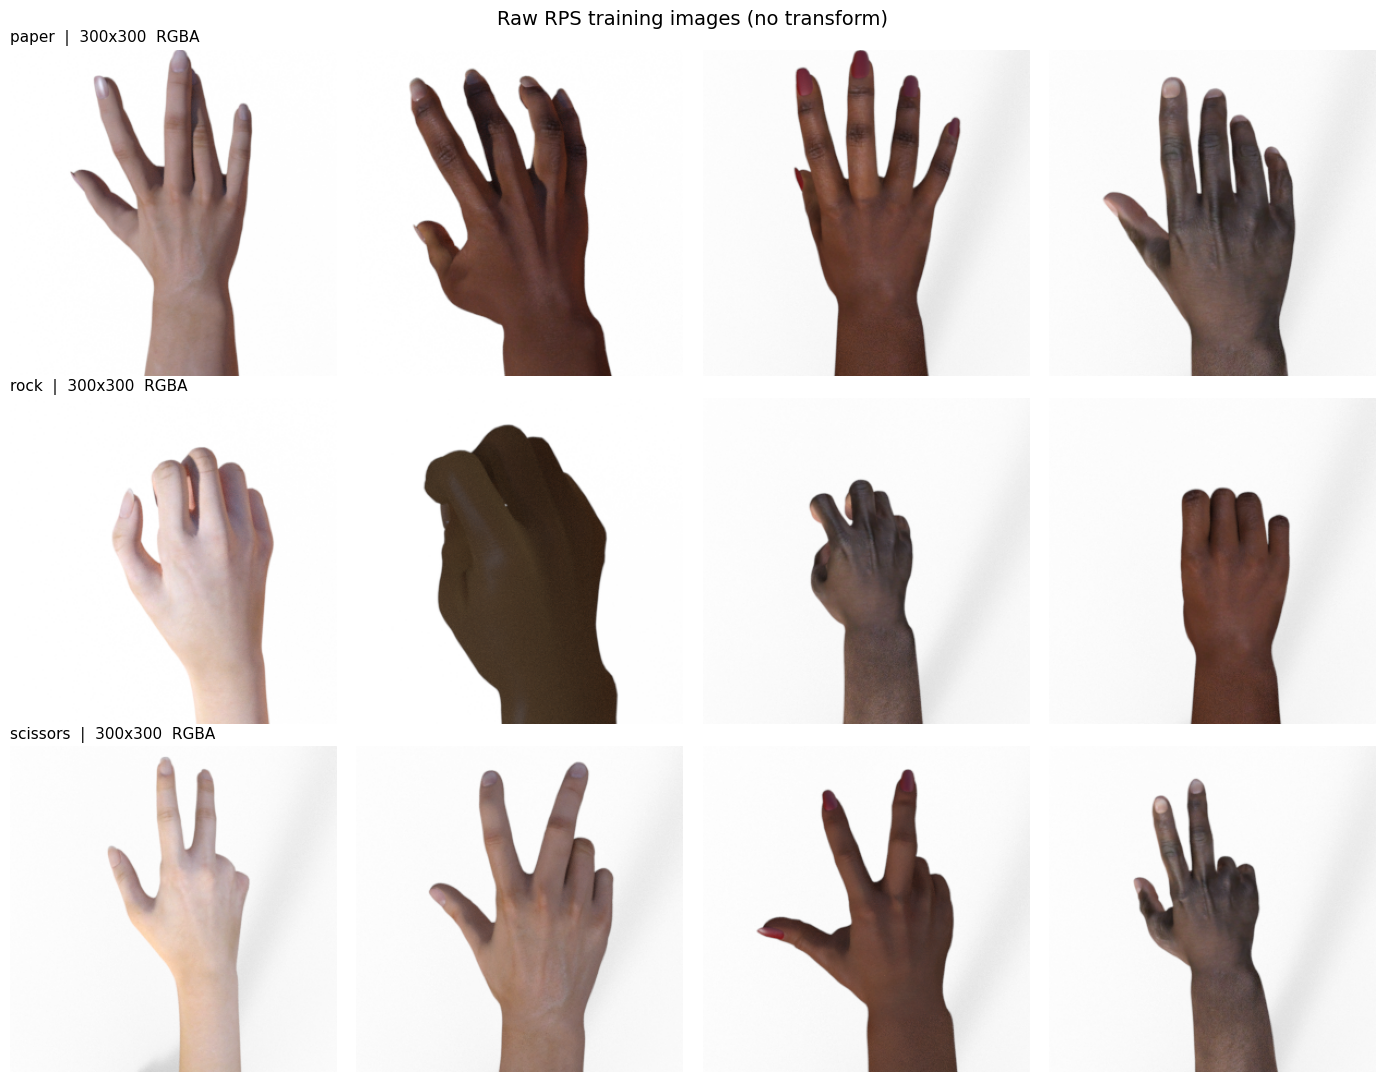

In [95]:
fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for row, cls in enumerate(CLASSES):
    paths = sorted(glob.glob(os.path.join(TRAIN_DIR, cls, "*.png")))
    print(f"{cls:9s}: {len(paths)} files | example: {os.path.basename(paths[0])}")


    picks = [paths[i] for i in np.linspace(0, len(paths) - 1, 4).astype(int)]

    for col, p in enumerate(picks):
        img = Image.open(p)
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(f"{cls}  |  {img.size[0]}x{img.size[1]}  {img.mode}",
                                     fontsize=11, loc="left")

plt.suptitle("Raw RPS training images (no transform)", fontsize=14)
plt.tight_layout()
plt.show()

# Visually compare fetched images with my custom images.

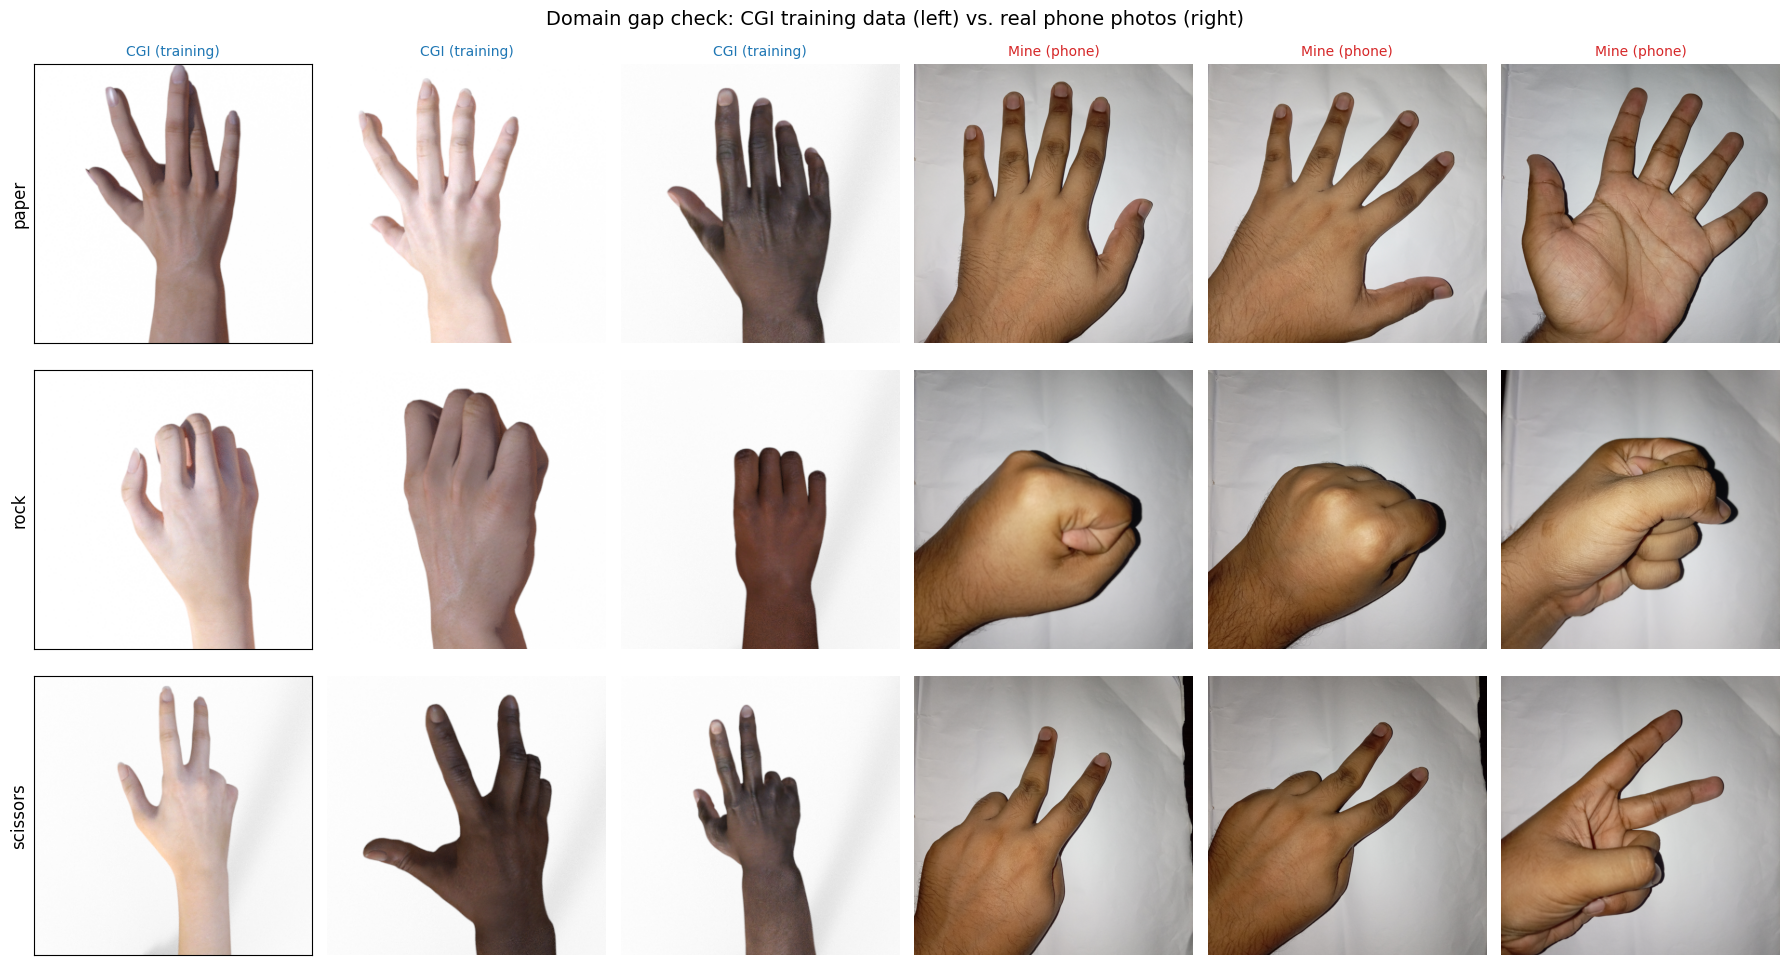

In [96]:
fig, axes = plt.subplots(3, 6, figsize=(18, 10))

for row, cls in enumerate(CLASSES):
    paths = sorted(glob.glob(os.path.join(TRAIN_DIR, cls, "*.png")))
    picks = [paths[i] for i in np.linspace(0, len(paths) - 1, 3).astype(int)]

    for col, p in enumerate(picks):
        axes[row, col].imshow(Image.open(p))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title("CGI (training)", fontsize=10, color="tab:blue")

    mine = sorted(glob.glob(os.path.join(CUSTOM_DIR, f"{cls}_*.jpg")))[:3]

    for col, p in enumerate(mine):
        img = Image.open(p)
        axes[row, col + 3].imshow(img)
        axes[row, col + 3].axis("off")
        if row == 0:
            axes[row, col + 3].set_title("Mine (phone)", fontsize=10, color="tab:red")

    axes[row, 0].set_ylabel(cls, fontsize=12)
    axes[row, 0].axis("on")
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

plt.suptitle("Domain gap check: CGI training data (left) vs. real phone photos (right)",
             fontsize=14)
plt.tight_layout()
plt.show()

# Now I will view raw pixels statistics.

In [97]:
def pixel_stats(paths, label):
    means, stds = [], []
    for p in paths:
        arr = np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) / 255.0
        means.append(arr.reshape(-1, 3).mean(axis=0))
        stds.append(arr.reshape(-1, 3).std(axis=0))
    m, s = np.mean(means, axis=0), np.mean(stds, axis=0)
    print(f"{label:<22} mean RGB = [{m[0]:.3f} {m[1]:.3f} {m[2]:.3f}]   "
          f"std RGB = [{s[0]:.3f} {s[1]:.3f} {s[2]:.3f}]")
    return means

cgi_paths = []
for cls in CLASSES:
    cgi_paths += sorted(glob.glob(os.path.join(TRAIN_DIR, cls, "*.png")))[::42][:20]

mine_paths = sorted(glob.glob(os.path.join(CUSTOM_DIR, "*.jpg")))

cgi_means  = pixel_stats(cgi_paths,  "CGI training (n=60)")
mine_means = pixel_stats(mine_paths, "My phone photos (n=10)")

CGI training (n=60)    mean RGB = [0.851 0.822 0.812]   std RGB = [0.223 0.268 0.283]
My phone photos (n=10) mean RGB = [0.637 0.588 0.531]   std RGB = [0.137 0.184 0.234]


# Histogram of overall brightness in CGI photos and my photos.

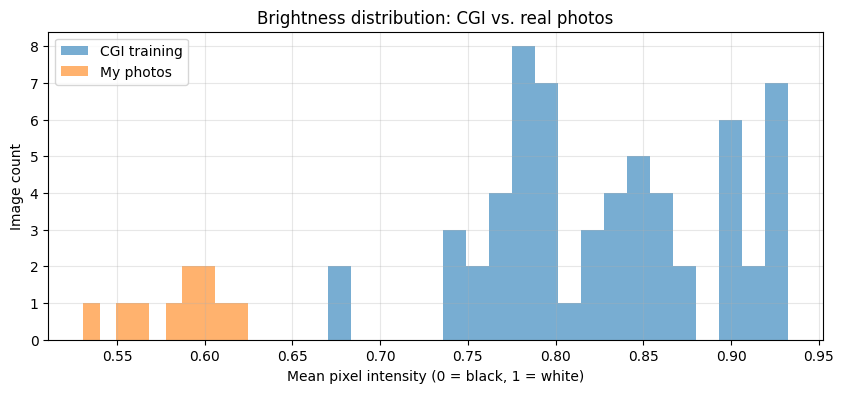

In [98]:
plt.figure(figsize=(10, 4))
plt.hist([np.mean(m) for m in cgi_means],  bins=20, alpha=0.6, label="CGI training")
plt.hist([np.mean(m) for m in mine_means], bins=10, alpha=0.6, label="My photos")
plt.xlabel("Mean pixel intensity (0 = black, 1 = white)")
plt.ylabel("Image count")
plt.title("Brightness distribution: CGI vs. real photos")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Now, I will perform data preprocessing.

# This is a pipeline for Resizing, Converting to tensor and normalizing the Validation, Test and My custom dataset.

In [99]:

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

# This is a pipiline for Resizing, Randomizeing image rotation and flip, Add random color jitter , converting to tensor, and normalizing the train dataset.
The rotation, flip and jitter helps make more variation in the data so that model gets more generalized and better.

In [100]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.4, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

# Now, I will build datasets and dataloaders.

# Split the training set into train and validation.

In [101]:
base = ImageFolder(root=TRAIN_DIR, transform=None)
print("Class -> index mapping:", base.class_to_idx)

n_total = len(base)
n_val   = int(0.2 * n_total)
n_train = n_total - n_val

train_set, val_set = random_split(base, [n_train, n_val])

train_set.dataset = copy.copy(base)
val_set.dataset   = copy.copy(base)

train_set.dataset.transform = train_transform
val_set.dataset.transform   = eval_transform

test_set = ImageFolder(root=TEST_DIR, transform=eval_transform)

Class -> index mapping: {'paper': 0, 'rock': 1, 'scissors': 2}


# Now I will set up the dataloaders. dataloaders is the way our model gets images in batches.

In [102]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\nTrain images : {len(train_set)}")
print(f"Val   images : {len(val_set)}")
print(f"Test  images : {len(test_set)}")
print(f"Batch size   : {BATCH_SIZE}")

images, labels = next(iter(train_loader))
print(f"\nBatch tensor shape : {tuple(images.shape)}")
print(f"Pixel range        : [{images.min():.2f}, {images.max():.2f}]")


Train images : 2016
Val   images : 504
Test  images : 372
Batch size   : 64

Batch tensor shape : (64, 3, 128, 128)
Pixel range        : [-1.00, 1.00]


# Now, I will see what changes were made to our images in preprocessing phase.

# I will create a method to denormalize the tensors to view the trandformed images, cause tensors must be converted back to view as an image.

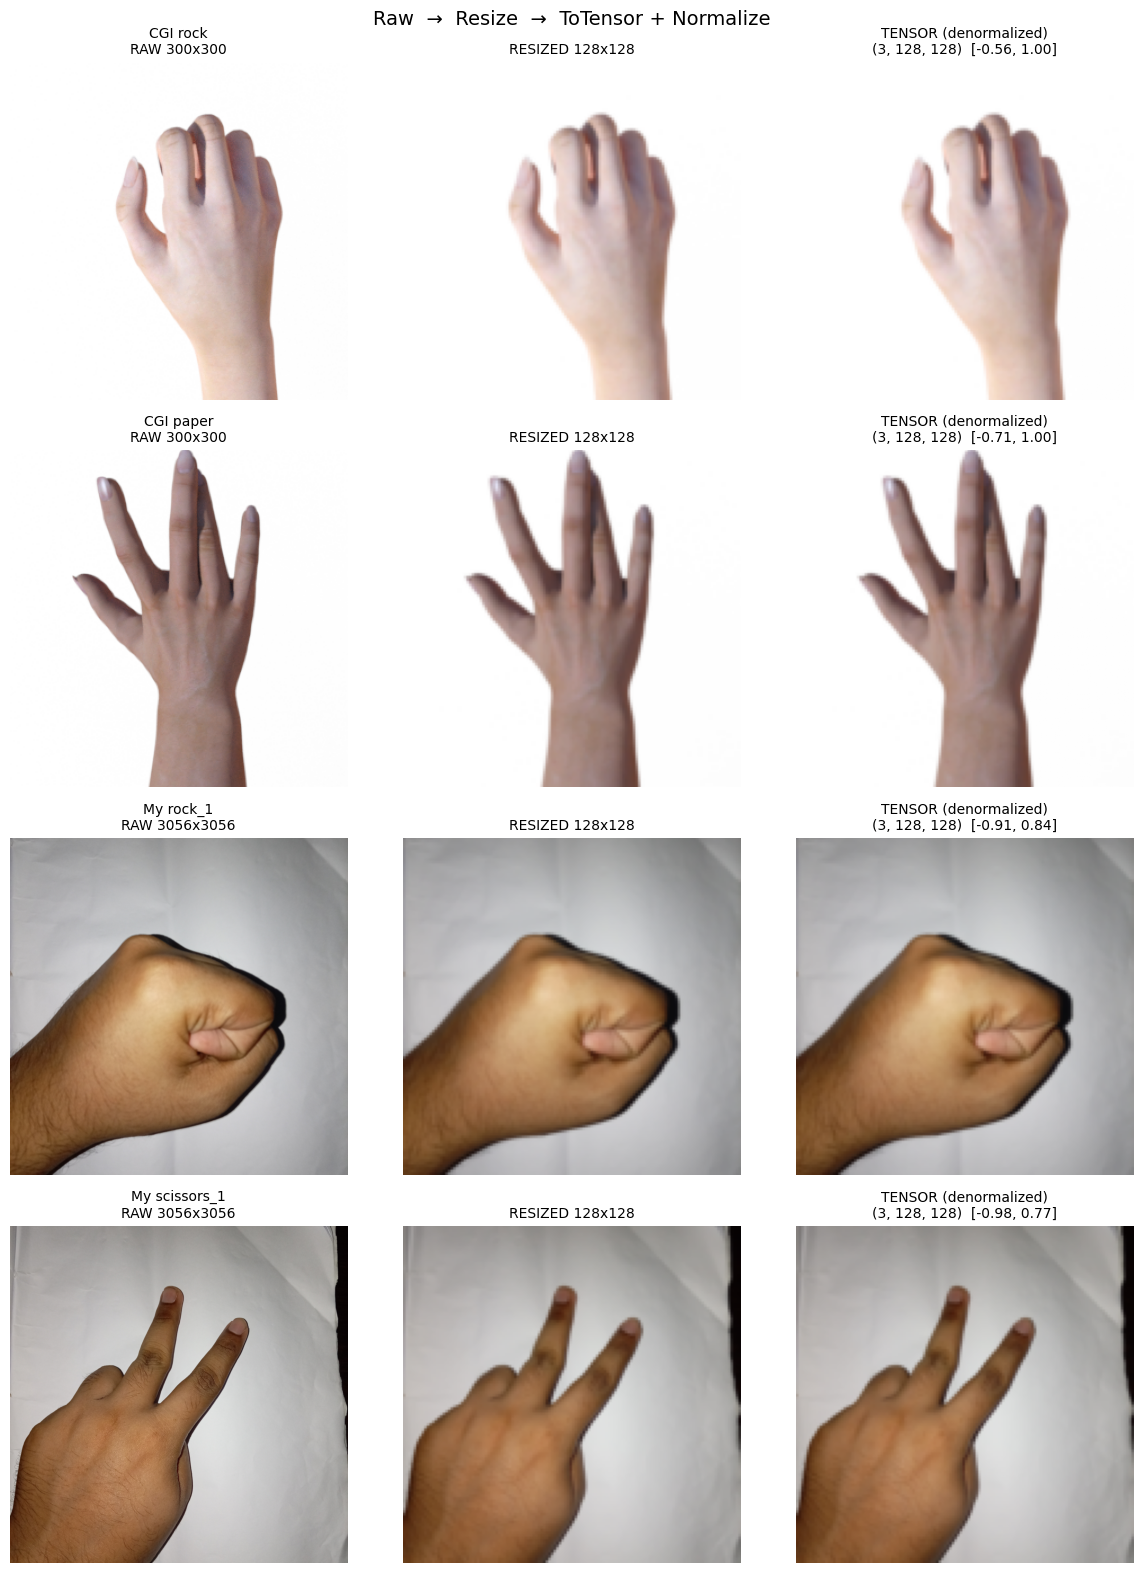

In [103]:
def denormalize(tensor):
    t = tensor.clone().cpu()
    for c in range(3):
        t[c] = t[c] * NORM_STD[c] + NORM_MEAN[c]
    return t.clamp(0, 1).permute(1, 2, 0).numpy()


samples = [
    (sorted(glob.glob(os.path.join(TRAIN_DIR, "rock",  "*.png")))[0], "CGI rock"),
    (sorted(glob.glob(os.path.join(TRAIN_DIR, "paper", "*.png")))[0], "CGI paper"),
    (os.path.join(CUSTOM_DIR, "rock_1.jpg"),                          "My rock_1"),
    (os.path.join(CUSTOM_DIR, "scissors_1.jpg"),                      "My scissors_1"),
]

fig, axes = plt.subplots(len(samples), 3, figsize=(12, 4 * len(samples)))

for row, (path, label) in enumerate(samples):
    raw     = Image.open(path).convert("RGB")
    resized = transforms.Resize((IMG_SIZE, IMG_SIZE))(raw)
    tensor  = eval_transform(raw)

    axes[row, 0].imshow(raw)
    axes[row, 0].set_title(f"{label}\nRAW {raw.size[0]}x{raw.size[1]}", fontsize=10)

    axes[row, 1].imshow(resized)
    axes[row, 1].set_title(f"RESIZED {IMG_SIZE}x{IMG_SIZE}", fontsize=10)

    axes[row, 2].imshow(denormalize(tensor))
    axes[row, 2].set_title(f"TENSOR (denormalized)\n{tuple(tensor.shape)}  "
                           f"[{tensor.min():.2f}, {tensor.max():.2f}]", fontsize=10)

    for c in range(3):
        axes[row, c].axis("off")

plt.suptitle("Raw  →  Resize  →  ToTensor + Normalize", fontsize=14)
plt.tight_layout(); plt.show()

# As we can see, the images has been reduced to 128x128 px resolution.

# Now we will see what normalization did to pixel distribution.

RAW PIL image
  shape (3056, 3056, 3)   dtype uint8   range [0, 242]

After ToTensor()
  shape (3, 128, 128)   dtype torch.float32
  range [0.043, 0.922]   mean 0.586

After Normalize()
  shape (3, 128, 128)   range [-0.914, 0.843]   mean 0.173


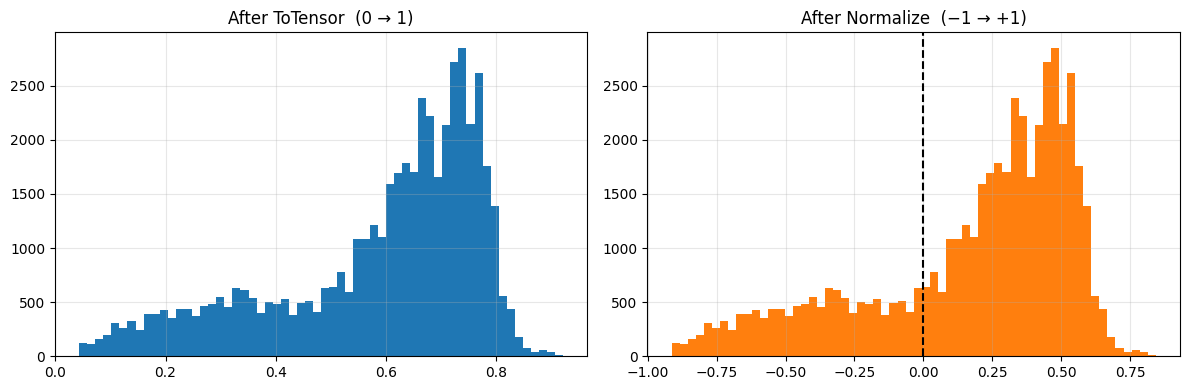

In [104]:
raw = Image.open(os.path.join(CUSTOM_DIR, "rock_1.jpg")).convert("RGB")

after_resize = transforms.Resize((IMG_SIZE, IMG_SIZE))(raw)
after_tensor = transforms.ToTensor()(after_resize)
after_norm   = transforms.Normalize(NORM_MEAN, NORM_STD)(after_tensor)

arr = np.asarray(raw)
print("RAW PIL image")
print(f"  shape {arr.shape}   dtype {arr.dtype}   range [{arr.min()}, {arr.max()}]\n")

print("After ToTensor()")
print(f"  shape {tuple(after_tensor.shape)}   dtype {after_tensor.dtype}")
print(f"  range [{after_tensor.min():.3f}, {after_tensor.max():.3f}]   mean {after_tensor.mean():.3f}\n")

print("After Normalize()")
print(f"  shape {tuple(after_norm.shape)}   range "
      f"[{after_norm.min():.3f}, {after_norm.max():.3f}]   mean {after_norm.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(after_tensor.numpy().ravel(), bins=60, color="tab:blue")
axes[0].set_title("After ToTensor  (0 → 1)"); axes[0].grid(alpha=0.3)
axes[1].hist(after_norm.numpy().ravel(), bins=60, color="tab:orange")
axes[1].axvline(0, color="k", ls="--")
axes[1].set_title("After Normalize  (−1 → +1)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Now, we will se what augmentation did, we will see an example over one image. Basically augmentation creates multiple roatated variants of one image so that model generalizes more.

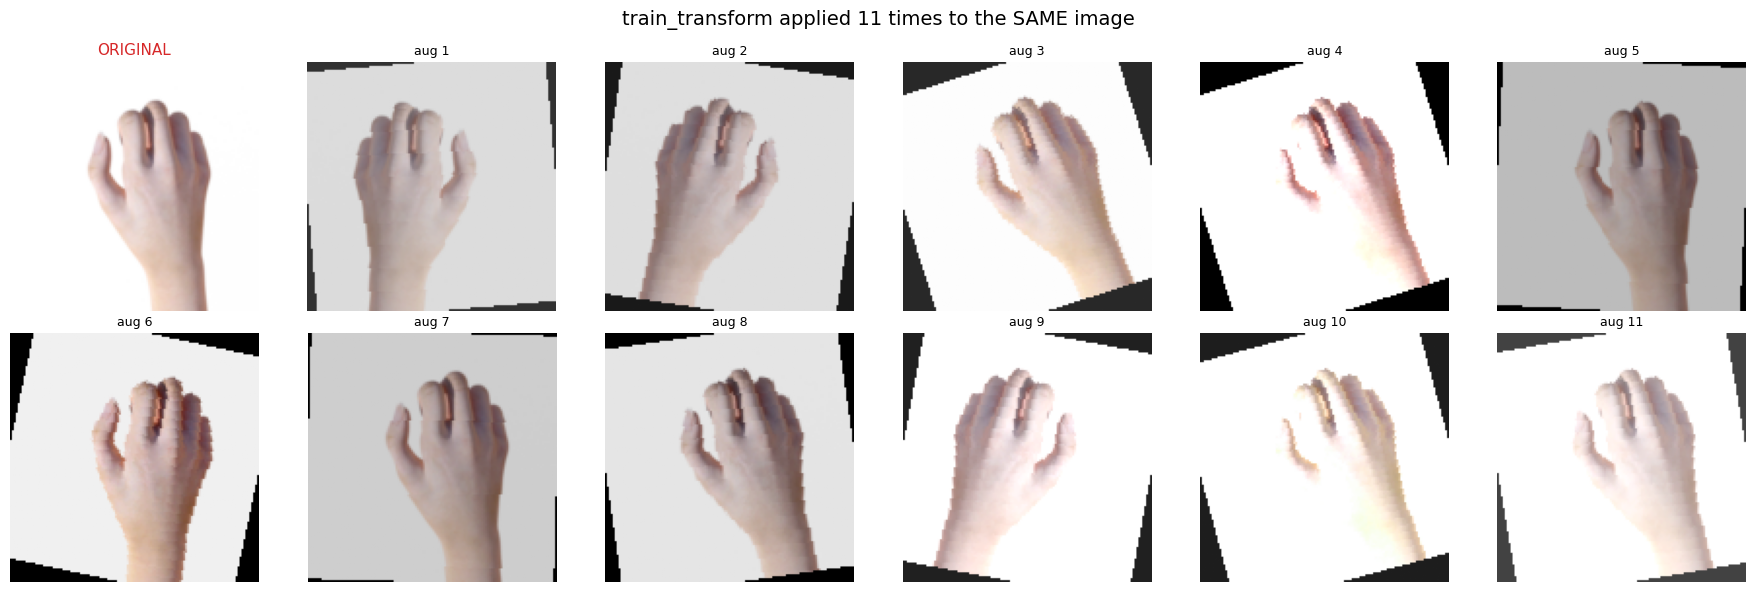

In [105]:

raw = Image.open(sorted(glob.glob(os.path.join(TRAIN_DIR, "rock", "*.png")))[0]).convert("RGB")

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

axes[0, 0].imshow(transforms.Resize((IMG_SIZE, IMG_SIZE))(raw))
axes[0, 0].set_title("ORIGINAL", fontsize=11, color="tab:red")
axes[0, 0].axis("off")

for i in range(1, 12):
    r, c = divmod(i, 6)
    axes[r, c].imshow(denormalize(train_transform(raw)))
    axes[r, c].set_title(f"aug {i}", fontsize=9)
    axes[r, c].axis("off")

plt.suptitle("train_transform applied 11 times to the SAME image", fontsize=14)
plt.tight_layout(); plt.show()

# Now we will build the CNN.

# This is the CNN architechture.

In [106]:
class CNN(nn.Module):
    def __init__(self, num_classes=3):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3,   32,  kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32,  64,  kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64,  128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))

        x = x.view(x.size(0), -1)

        x = self.dropout(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


model = CNN(num_classes=len(CLASSES)).to(DEVICE)
print(model)

print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

dummy = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
print("Output shape:", tuple(model(dummy).shape))

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)

Total parameters: 2,339,715
Output shape: (4, 3)


# Set up Loss Function, Optimizer, and Training/Evaluation Loops. We will use them later.

In [107]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

print("Loss     :", criterion)
print("Optimizer:", type(optimizer).__name__, "| lr =", LR)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)

    return running_loss / total, 100.0 * correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

    return running_loss / total, 100.0 * correct / total

Loss     : CrossEntropyLoss()
Optimizer: Adam | lr = 0.001


# This is the training loop (loads saved weights + history if available).

In [108]:
MODEL_DIR    = os.path.join(REPO_DIR, "model")
MODEL_PATH   = os.path.join(MODEL_DIR, f"{STUDENT_ID}.pth")
HISTORY_PATH = os.path.join(MODEL_DIR, f"{STUDENT_ID}_history.json")

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

if os.path.exists(MODEL_PATH):
    print(f"Found saved weights at {MODEL_PATH} — loading instead of retraining.")
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    model.to(DEVICE)
    TRAINED_NOW = False

    if os.path.exists(HISTORY_PATH):
        with open(HISTORY_PATH) as f:
            history = json.load(f)
        print(f"History loaded from: {HISTORY_PATH}  ({len(history['train_loss'])} epochs)")
    else:
        print("WARNING: no history file found — training plots will be empty.")

else:
    print(f"No saved weights found. Training for {EPOCHS} epochs...\n")
    TRAINED_NOW = True
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        va_loss, va_acc = evaluate(model, val_loader, criterion, DEVICE)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        print(f"Epoch {epoch:2d}/{EPOCHS} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:5.2f}% | "
              f"val loss {va_loss:.4f} acc {va_acc:5.2f}%")

    print(f"\nTraining finished in {time.time() - start:.1f}s")

    os.makedirs(MODEL_DIR, exist_ok=True)
    torch.save(model.state_dict(), MODEL_PATH)
    print(f"Model saved to: {MODEL_PATH}")

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f)
    print(f"History saved to: {HISTORY_PATH}")

No saved weights found. Training for 15 epochs...

Epoch  1/15 | train loss 1.8033 acc 45.04% | val loss 0.9745 acc 51.59%
Epoch  2/15 | train loss 0.5851 acc 77.33% | val loss 0.2928 acc 93.25%
Epoch  3/15 | train loss 0.2976 acc 91.07% | val loss 0.1471 acc 96.83%
Epoch  4/15 | train loss 0.1738 acc 95.73% | val loss 0.1177 acc 98.61%
Epoch  5/15 | train loss 0.1188 acc 97.17% | val loss 0.0300 acc 99.80%
Epoch  6/15 | train loss 0.0678 acc 98.21% | val loss 0.0091 acc 100.00%
Epoch  7/15 | train loss 0.0495 acc 99.06% | val loss 0.0095 acc 99.80%
Epoch  8/15 | train loss 0.0439 acc 98.56% | val loss 0.0050 acc 100.00%
Epoch  9/15 | train loss 0.0300 acc 99.16% | val loss 0.0047 acc 99.80%
Epoch 10/15 | train loss 0.0254 acc 99.26% | val loss 0.0013 acc 100.00%
Epoch 11/15 | train loss 0.0174 acc 99.65% | val loss 0.0019 acc 100.00%
Epoch 12/15 | train loss 0.0230 acc 99.45% | val loss 0.0010 acc 100.00%
Epoch 13/15 | train loss 0.0200 acc 99.45% | val loss 0.0018 acc 100.00%
Epoch 1

# Evaluation Phase.

# Now, I will evalutate the model over out test set.

In [109]:
model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        _, preds = outputs.max(1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = 100.0 * (all_preds == all_labels).mean()
print(f"Test accuracy: {test_acc:.2f}%  ({(all_preds == all_labels).sum()}/{len(all_labels)})")

print("\nPer-class accuracy:")
for i, cls in enumerate(CLASSES):
    mask = all_labels == i
    acc  = 100.0 * (all_preds[mask] == all_labels[mask]).mean()
    print(f"  {cls:9s}: {acc:6.2f}%   ({(all_preds[mask] == all_labels[mask]).sum()}/{mask.sum()})")

from sklearn.metrics import classification_report
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))

Test accuracy: 92.20%  (343/372)

Per-class accuracy:
  paper    :  83.06%   (103/124)
  rock     : 100.00%   (124/124)
  scissors :  93.55%   (116/124)
              precision    recall  f1-score   support

       paper     0.9717    0.8306    0.8957       124
        rock     0.8732    1.0000    0.9323       124
    scissors     0.9355    0.9355    0.9355       124

    accuracy                         0.9220       372
   macro avg     0.9268    0.9220    0.9212       372
weighted avg     0.9268    0.9220    0.9212       372



# Let's generate training history plots (Loss and accuracy vs epochs).

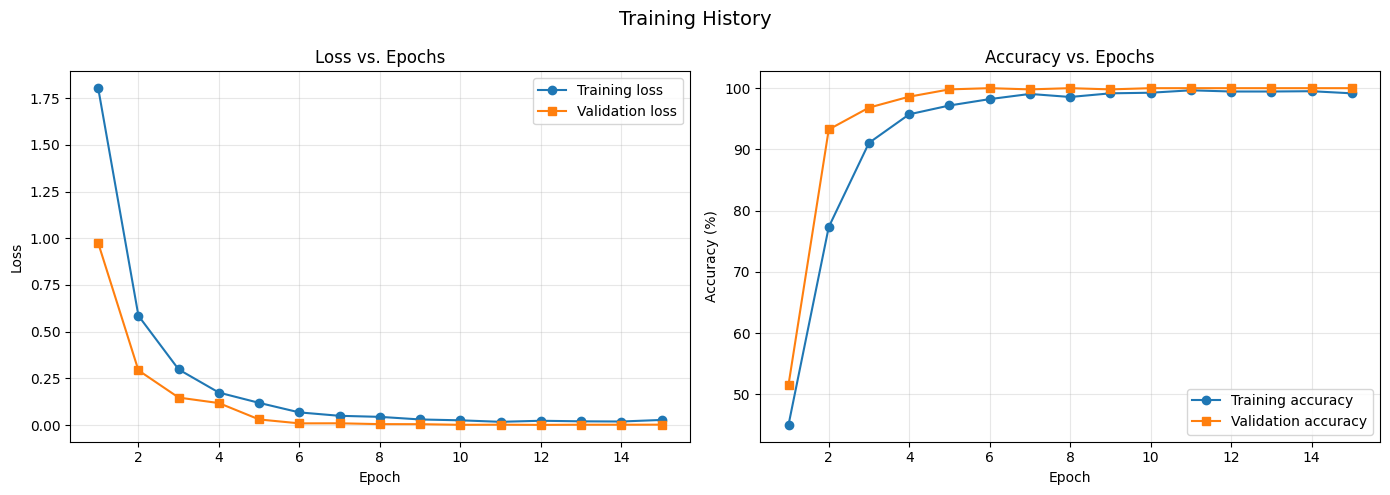

Final training accuracy   : 99.16%
Final validation accuracy : 100.00%
Lowest validation loss    : 0.0010 (epoch 12)


In [110]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].plot(epochs, history["train_loss"], "o-", label="Training loss")
axes[0].plot(epochs, history["val_loss"],   "s-", label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss vs. Epochs")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_acc"], "o-", label="Training accuracy")
axes[1].plot(epochs, history["val_acc"],   "s-", label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Accuracy vs. Epochs")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Training History", fontsize=14)
plt.tight_layout()
plt.savefig("training_history.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Final training accuracy   : {history['train_acc'][-1]:.2f}%")
print(f"Final validation accuracy : {history['val_acc'][-1]:.2f}%")
print(f"Lowest validation loss    : {min(history['val_loss']):.4f} "
      f"(epoch {history['val_loss'].index(min(history['val_loss'])) + 1})")

# Let's get confusion matrix over the test set.

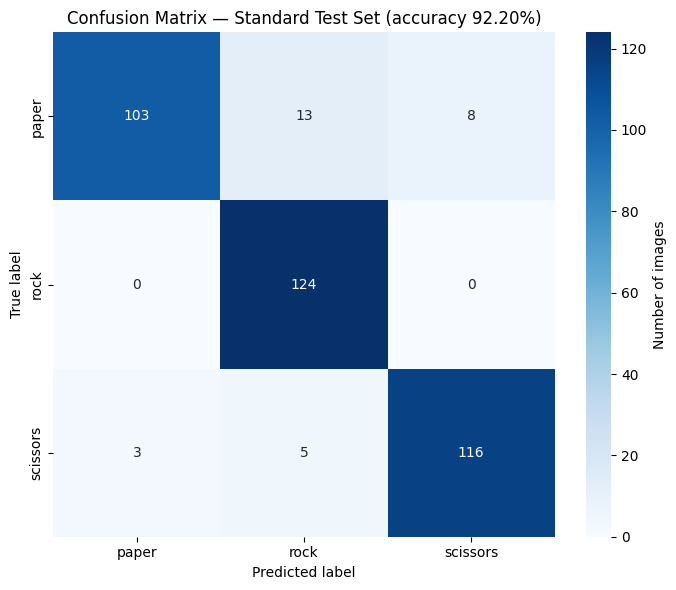


Raw counts:
 [[103  13   8]
 [  0 124   0]
 [  3   5 116]]


In [111]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES,
            cbar_kws={"label": "Number of images"})
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Confusion Matrix — Standard Test Set (accuracy {test_acc:.2f}%)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

print("\nRaw counts:\n", cm)

# Now I'll get predictions over my custom images.

In [112]:
custom_files = sorted([f for f in os.listdir(CUSTOM_DIR) if f.endswith(".jpg")])

model.eval()

results = []

with torch.no_grad():
    for fname in custom_files:
        path = os.path.join(CUSTOM_DIR, fname)

        img = Image.open(path).convert("RGB")
        tensor = eval_transform(img)
        tensor = tensor.unsqueeze(0).to(DEVICE)

        logits = model(tensor)
        probs  = torch.softmax(logits, dim=1)[0]

        pred_idx  = probs.argmax().item()
        pred_cls  = CLASSES[pred_idx]
        confidence = probs[pred_idx].item() * 100

        true_cls = fname.split("_")[0]

        results.append({
            "file": fname,
            "image": img,
            "true": true_cls,
            "pred": pred_cls,
            "conf": confidence,
            "probs": probs.cpu().numpy(),
            "correct": pred_cls == true_cls,
        })

n_correct = sum(r["correct"] for r in results)
print(f"Custom image accuracy: {n_correct}/{len(results)} = {100*n_correct/len(results):.1f}%\n")

print(f"{'file':<18}{'true':<10}{'pred':<10}{'conf':>8}   {'':<3}  all probabilities")
print("-" * 78)
for r in results:
    mark = "OK " if r["correct"] else "MISS"
    probs_str = "  ".join(f"{c[:4]}:{p*100:5.1f}%" for c, p in zip(CLASSES, r["probs"]))
    print(f"{r['file']:<18}{r['true']:<10}{r['pred']:<10}{r['conf']:>7.1f}%  {mark}  {probs_str}")

Custom image accuracy: 9/10 = 90.0%

file              true      pred          conf        all probabilities
------------------------------------------------------------------------------
paper_1.jpg       paper     paper       100.0%  OK   pape:100.0%  rock:  0.0%  scis:  0.0%
paper_2.jpg       paper     paper       100.0%  OK   pape:100.0%  rock:  0.0%  scis:  0.0%
paper_3.jpg       paper     paper        99.2%  OK   pape: 99.2%  rock:  0.1%  scis:  0.7%
rock_1.jpg        rock      rock        100.0%  OK   pape:  0.0%  rock:100.0%  scis:  0.0%
rock_2.jpg        rock      rock        100.0%  OK   pape:  0.0%  rock:100.0%  scis:  0.0%
rock_3.jpg        rock      rock        100.0%  OK   pape:  0.0%  rock:100.0%  scis:  0.0%
rock_4.jpg        rock      rock        100.0%  OK   pape:  0.0%  rock:100.0%  scis:  0.0%
scissors_1.jpg    scissors  scissors     99.7%  OK   pape:  0.3%  rock:  0.0%  scis: 99.7%
scissors_2.jpg    scissors  scissors     99.9%  OK   pape:  0.1%  rock:  0.1%  scis:

# Custom predictions gallery.

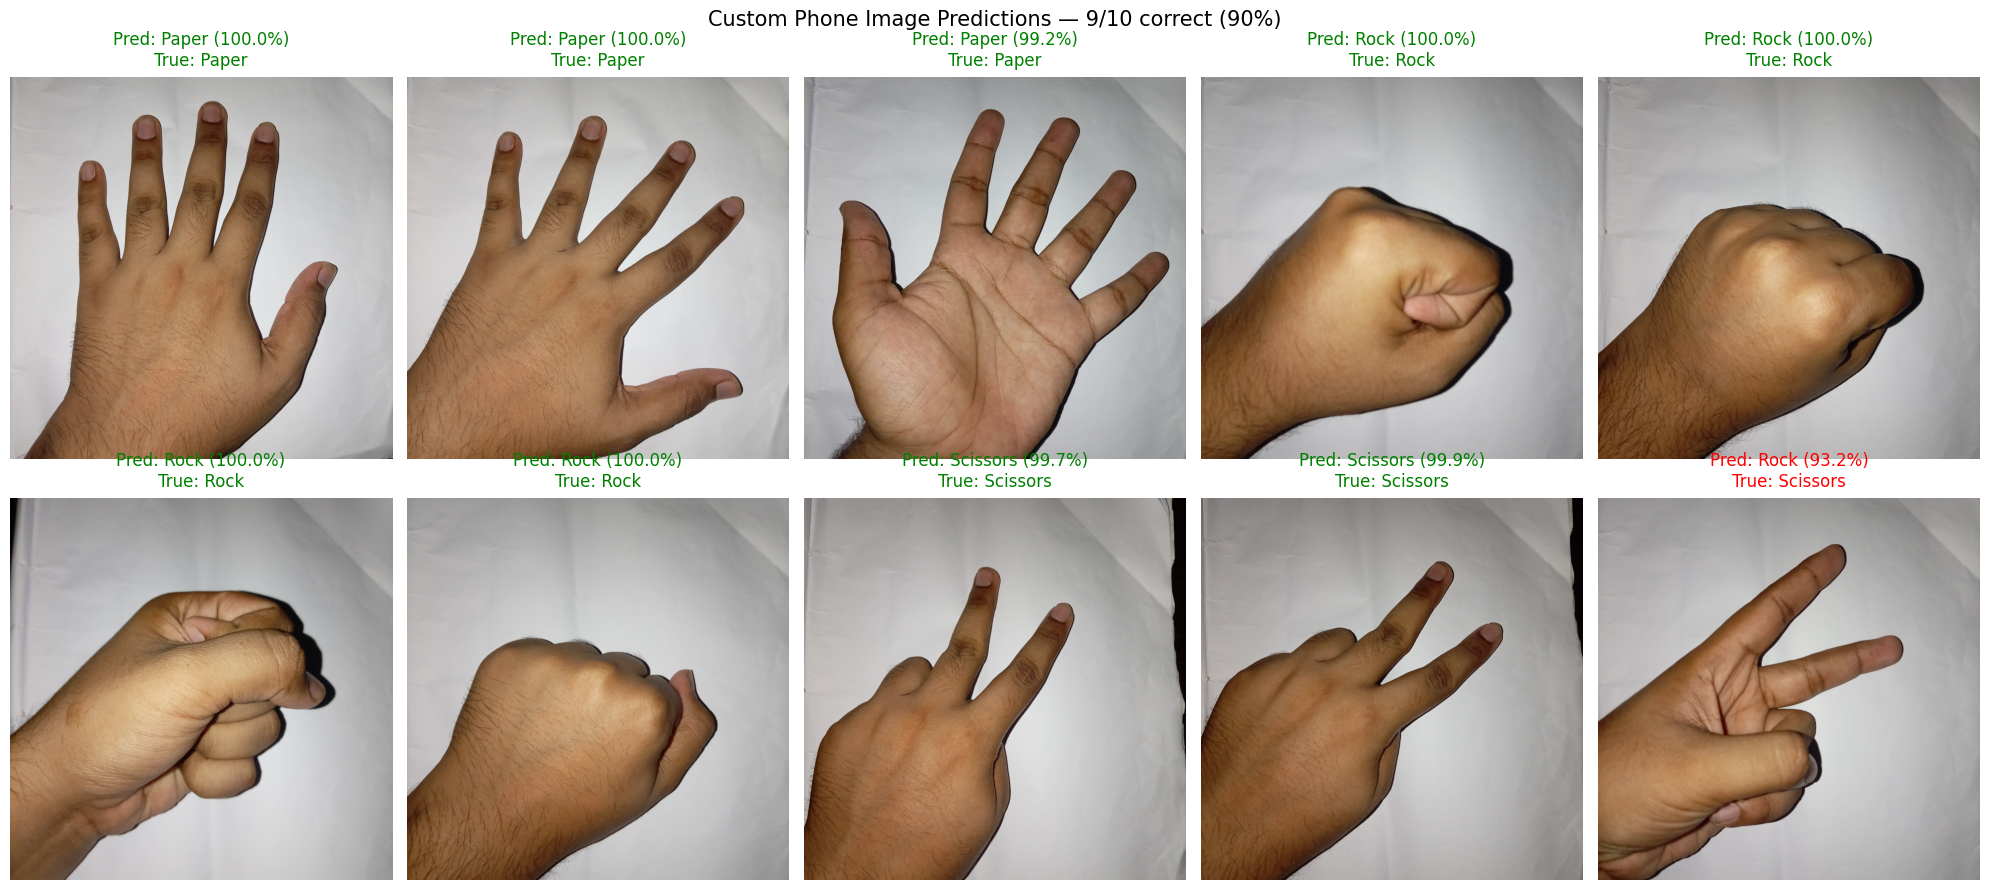

In [113]:
n = len(results)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.6 * rows))
axes = np.array(axes).reshape(-1)

for i, r in enumerate(results):
    ax = axes[i]
    ax.imshow(r["image"])
    ax.axis("off")

    colour = "green" if r["correct"] else "red"
    ax.set_title(f"Pred: {r['pred'].capitalize()} ({r['conf']:.1f}%)\n"
                 f"True: {r['true'].capitalize()}",
                 fontsize=12, color=colour, pad=8)

for j in range(n, len(axes)):
    axes[j].axis("off")

n_correct = sum(r["correct"] for r in results)
plt.suptitle(f"Custom Phone Image Predictions — {n_correct}/{n} correct "
             f"({100*n_correct/n:.0f}%)", fontsize=15)
plt.tight_layout()
plt.savefig("custom_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

# Visual Error Analysis.

Total misclassified: 29 / 372


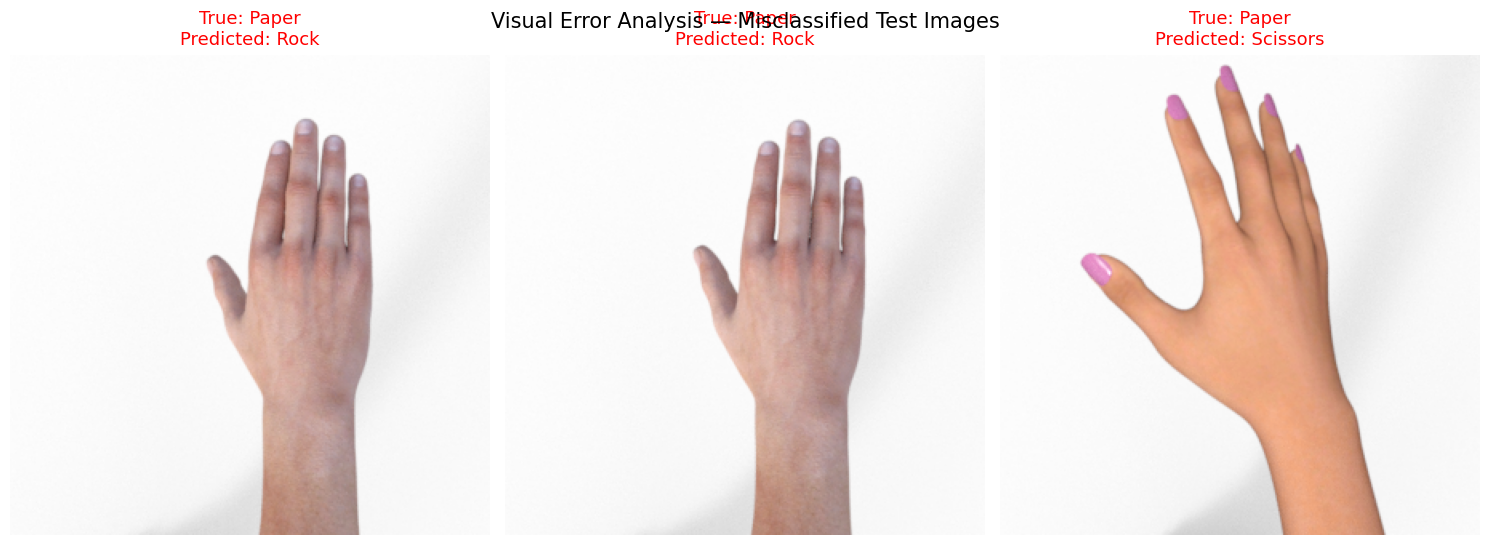


All misclassifications:
  testpaper01-00.png             true: paper     pred: scissors
  testpaper01-01.png             true: paper     pred: scissors
  testpaper01-02.png             true: paper     pred: scissors
  testpaper01-03.png             true: paper     pred: scissors
  testpaper01-04.png             true: paper     pred: scissors
  testpaper01-05.png             true: paper     pred: scissors
  testpaper01-06.png             true: paper     pred: scissors
  testpaper01-07.png             true: paper     pred: scissors
  testpaper03-00.png             true: paper     pred: rock
  testpaper03-01.png             true: paper     pred: rock
  testpaper03-02.png             true: paper     pred: rock
  testpaper03-03.png             true: paper     pred: rock
  testpaper03-04.png             true: paper     pred: rock
  testpaper03-05.png             true: paper     pred: rock
  testpaper03-06.png             true: paper     pred: rock
  testpaper03-07.png             true: pape

In [114]:
wrong_idx = np.where(all_preds != all_labels)[0]
print(f"Total misclassified: {len(wrong_idx)} / {len(all_labels)}")

if len(wrong_idx) == 0:
    print("No misclassifications on the test set.")
else:
    picks = random.sample(list(wrong_idx), min(3, len(wrong_idx)))

    fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 5.5))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, picks):
        path, _ = test_set.samples[idx]
        img = Image.open(path).convert("RGB")

        true_cls = CLASSES[all_labels[idx]]
        pred_cls = CLASSES[all_preds[idx]]

        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"True: {true_cls.capitalize()}\n"
                     f"Predicted: {pred_cls.capitalize()}",
                     fontsize=13, color="red", pad=8)

    plt.suptitle("Visual Error Analysis — Misclassified Test Images", fontsize=15)
    plt.tight_layout()
    plt.savefig("error_analysis.png", dpi=120, bbox_inches="tight")
    plt.show()

    print("\nAll misclassifications:")
    for idx in wrong_idx:
        fname = os.path.basename(test_set.samples[idx][0])
        print(f"  {fname:<30} true: {CLASSES[all_labels[idx]]:<9} "
              f"pred: {CLASSES[all_preds[idx]]}")

# **Summary of Findings**

# Dataset

Training set: 2,520 CGI images (840 each of paper/rock/scissors)

Train - Validation split 80/20 - 2,016 train - 504 validation images

Test set: 372 CGI images (124 per class)

Custom set: 10 real phone photos (3 paper, 4 rock, 3 scissors)

All images resized to 128×128, normalized to [-1, 1]

# Domain gap (CGI vs. phone photos)

Phone photos are noticeably darker and less varied in brightness than the CGI training data and it's visible in the brightness histogram as two separate clusters.

# Test set evaluation

Test accuracy: 92.20%  (343/372)

Per-class accuracy:

    paper    :  83.06%   (103/124)
    rock     : 100.00%   (124/124)
    scissors :  93.55%   (116/124)

Precision

    paper    :  0.9717
    rock     :  0.8732
    scissors :  0.9355

Recall

    paper    :  0.8306
    rock     :  1.0000
    scissors :  0.9355

f1-score

    paper    :  0.8957
    rock     :  0.9323
    scissors :  0.9355


# Custom image evaluation

    Custom image accuracy: 9/10 = 90.0%

#Overall

Our model actually performed well in both test set evaluation and custom dataset evaluation. Our custom images was not CGI like the train images, still the model managed to achieve 80% accuracy.
